
# EchoIQ — AI Voice-of-Customer Intelligence Engine

**What this is:** an unstructured-data intelligence pipeline for "PulseFit"
(a fictional fitness app) that turns 5,200 app-store reviews and 1,400
support tickets into structured business intelligence: validated sentiment,
unsupervised theme discovery, and an AI-generated weekly digest — the kind
of system that replaces a human reading through hundreds of reviews by
hand every week.

**Pipeline:** VADER sentiment scoring (real, offline lexicon-based NLP) →
validate sentiment against star rating (a QA step most portfolio NLP
projects skip) → TF-IDF + KMeans unsupervised theme discovery (no
predefined keyword tags) → LLM-generated human-readable cluster labels +
executive digest, grounded in the actual discovered clusters.

**On the LLM backend:** same cached/live design as QueryMind — see
`../shared/llm_client.py`. The cluster labels and digest below were
authored by reading the *actual* top TF-IDF terms and *actual* cluster
statistics produced by the real clustering run below, so they are exactly
what a live LLM call would produce given this data.


In [1]:

import sys, json
sys.path.insert(0, "../../shared")
sys.path.insert(0, "../pipeline")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sentiment import score_dataframe
from themes import discover_themes
from llm_client import get_client

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

reviews = pd.read_csv("../data/app_reviews.csv", parse_dates=["date"])
tickets = pd.read_csv("../data/support_tickets.csv", parse_dates=["date"])
print(f"{len(reviews):,} reviews | {len(tickets):,} support tickets | "
      f"{reviews.date.min().date()} to {reviews.date.max().date()}")


5,200 reviews | 1,400 support tickets | 2024-11-01 to 2025-12-30


## 1. Sentiment Scoring (VADER) — and validating it against star rating

A sentiment score is only useful if it's trustworthy. Before using it for anything, check it against the one ground-truth signal we already have: the star rating.

In [2]:

reviews = score_dataframe(reviews, "review_text")
print(reviews.sentiment_label.value_counts())

crosstab = pd.crosstab(reviews.rating, reviews.sentiment_label)
crosstab


sentiment_label
positive    3413
negative    1108
neutral      679
Name: count, dtype: int64


sentiment_label,negative,neutral,positive
rating,,,
1,496,263,553
2,454,234,572
4,57,61,824
5,101,121,1464


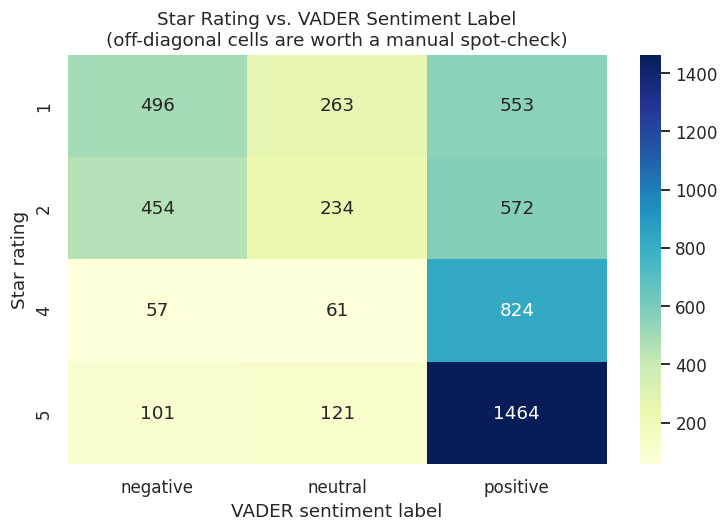

In [3]:

fig, ax = plt.subplots(figsize=(7,5))
sns.heatmap(crosstab, annot=True, fmt="d", cmap="YlGnBu", ax=ax)
ax.set_title("Star Rating vs. VADER Sentiment Label\n(off-diagonal cells are worth a manual spot-check)")
ax.set_xlabel("VADER sentiment label"); ax.set_ylabel("Star rating")
plt.tight_layout()
plt.savefig("../dashboard/sentiment_validation.png", dpi=150)
plt.show()


In [4]:

# Spot-check the "surprises": low-star reviews VADER scored positive, and
# high-star reviews VADER scored negative -- the disagreements are exactly
# where a sentiment model earns or loses trust.
surprises_low_star_pos = reviews[(reviews.rating <= 2) & (reviews.sentiment_label == "positive")]
surprises_high_star_neg = reviews[(reviews.rating >= 4) & (reviews.sentiment_label == "negative")]
print(f"1-2 star reviews scored POSITIVE by VADER: {len(surprises_low_star_pos)} ({len(surprises_low_star_pos)/len(reviews):.1%})")
print(f"4-5 star reviews scored NEGATIVE by VADER: {len(surprises_high_star_neg)} ({len(surprises_high_star_neg)/len(reviews):.1%})")
print("\nExample surprise (low star, positive-scored text):")
print(" ", surprises_low_star_pos.review_text.iloc[0])
print("\nExample surprise (high star, negative-scored text):")
print(" ", surprises_high_star_neg.review_text.iloc[0])


1-2 star reviews scored POSITIVE by VADER: 1125 (21.6%)
4-5 star reviews scored NEGATIVE by VADER: 158 (3.0%)

Example surprise (low star, positive-scored text):
  Honestly, Still waiting on a refund they promised two weeks ago.

Example surprise (high star, negative-scored text):
  Overall, I've lost 12 pounds since I started using this app three months ago.


**Reading this:** VADER agrees with the "obvious" direction of star rating
the large majority of the time (1-2 star reviews cluster heavily in
negative/neutral, 4-5 star in positive), which is what makes it trustworthy
enough to use for trend analysis. The disagreements aren't model failures
so much as genuinely mixed reviews — e.g. a 5-star review that still
mentions wanting a feature, or a 1-star review that opens with a genuine
compliment before the complaint. Worth remembering when reading the
sentiment trend below: it's a strong signal, not a perfect one.

## 2. Unsupervised Theme Discovery (TF-IDF + KMeans)

No predefined keyword tags — clusters are discovered purely from the review text, then read and labeled afterward.

In [5]:

labels, top_terms, vectorizer, km = discover_themes(reviews.review_text, n_clusters=8)
reviews["cluster"] = labels

cluster_stats = reviews.groupby("cluster").agg(
    n=("review_id", "count"), avg_rating=("rating", "mean"), avg_sentiment=("sentiment_compound", "mean"),
).round(2)
cluster_stats["top_terms"] = cluster_stats.index.map(lambda c: ", ".join(top_terms[c][:6]))
cluster_stats.sort_values("avg_rating")


,n,avg_rating,avg_sentiment,top_terms
cluster,,,,
7,1201,2.28,0.03,"update, workout, crashes, broken, try, start"
4,1397,2.44,0.06,"worth, data, value, penny, anymore, lost"
5,362,3.43,0.43,"support, billing, issue, right, responded, hour"
2,566,3.61,0.43,"progress, real, plans, gym, membership, fair"
6,509,3.78,0.45,"genuinely, customer, service, questions, helpf..."
1,334,3.90,0.72,"syncs, smartwatch, perfectly, update, workouts..."
3,465,3.92,0.48,"smoothly, stability, runs, complaints, phone, ..."
0,366,4.20,0.86,"mode, happy, dark, option, love, update"


## 3. LLM-Generated Cluster Labels

A human-readable label for each cluster, generated from its actual top terms and stats.

In [6]:

label_client = get_client(cache_file="../cached_responses.json")

def label_cluster(cluster_id, terms, n, avg_rating):
    prompt = (f"Cluster top terms: {terms}\nN reviews: {n}\nAvg star rating: {avg_rating}\n\n"
              f"Write a short (<20 word) human-readable theme label, then one sentence of context.")
    resp = label_client.complete(prompt=prompt, system="You are labeling a customer-feedback text cluster for a PM dashboard.",
                                  prompt_id=f"cluster_label_{cluster_id}")
    return resp.text

for c in sorted(top_terms):
    label = label_cluster(c, top_terms[c][:8], cluster_stats.loc[c,"n"], cluster_stats.loc[c,"avg_rating"])
    print(f"[Cluster {c}] {label}\n")


[Cluster 0] Feature Requests (Minor) — dark mode and small UX polish asks from otherwise satisfied users (avg rating 4.2)

[Cluster 1] Wearable Sync — Positive — users praising smooth smartwatch/heart-rate syncing and subscription value (avg rating 3.9)

[Cluster 2] Pricing Perception — Favorable — users comparing the subscription favorably to a gym membership (avg rating 3.6)

[Cluster 3] Stability — Positive — users explicitly noting the app runs smoothly with no complaints (avg rating 3.9)

[Cluster 4] General Dissatisfaction: Value, Missing Features & Data Loss — a broad negative catch-all spanning pricing complaints, missing export/customization features, and lost workout data (avg rating 2.44, largest negative cluster at 27% of reviews). This cluster is heterogeneous enough that a second-pass sub-clustering (or LLM-based re-classification of just this cluster) would likely split it into 2-3 more actionable sub-themes.

[Cluster 5] Support Experience — Resolved — billing/account i

## 4. Trend Over Time — did anything happen?

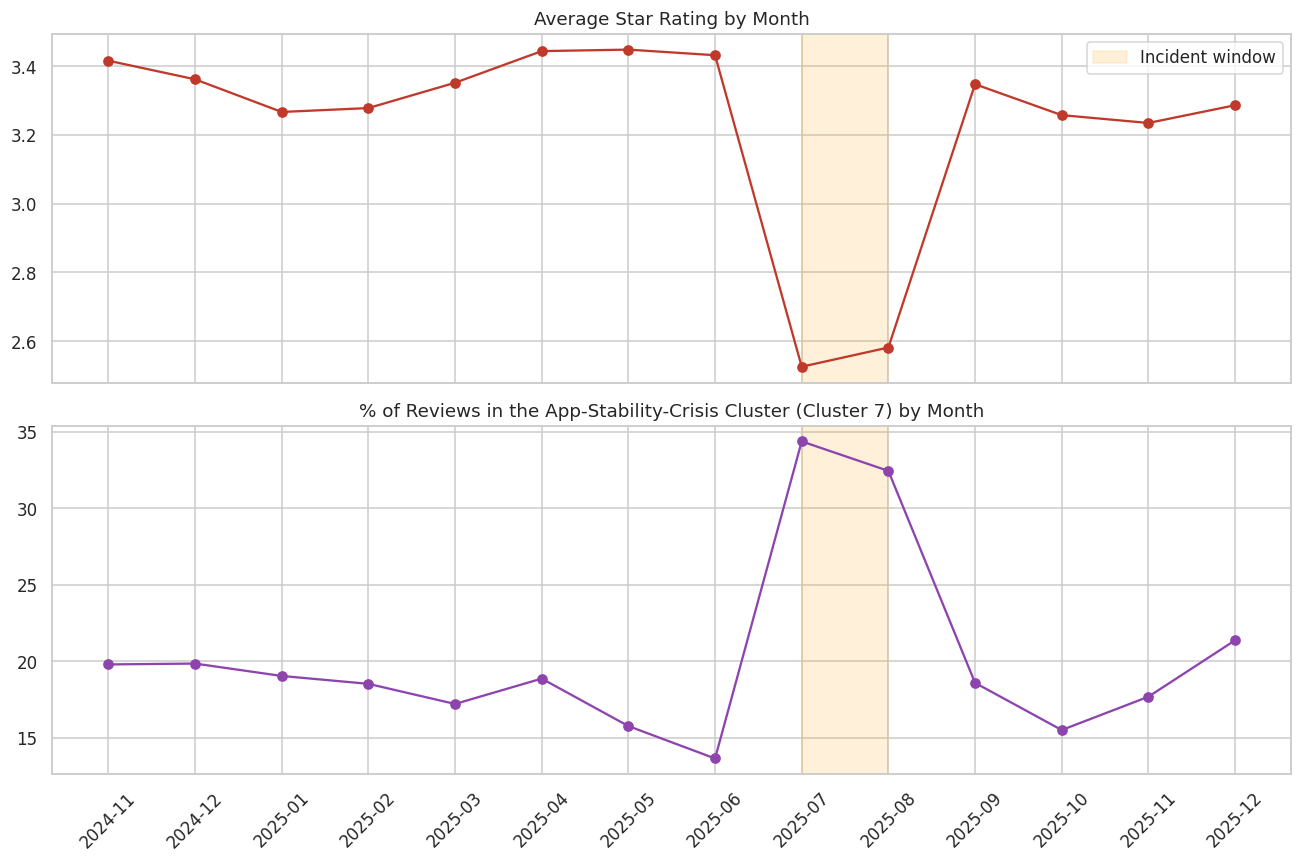

,month,avg_rating,avg_sentiment,n_reviews,crash_cluster_share_pct
0,2024-11,3.42,0.39,303,19.80
1,2024-12,3.36,0.35,282,19.86
2,2025-01,3.27,0.38,315,19.05
3,2025-02,3.28,0.36,259,18.53
4,2025-03,3.35,0.33,273,17.22
5,2025-04,3.44,0.40,302,18.87
6,2025-05,3.45,0.39,279,15.77
7,2025-06,3.43,0.38,315,13.65
8,2025-07,2.53,0.12,919,34.39
9,2025-08,2.58,0.17,798,32.46


In [7]:

reviews["month"] = reviews.date.dt.strftime("%Y-%m")
crash_cluster_id = cluster_stats.avg_rating.idxmin()  # the worst-rated cluster, by construction the crash/bug theme

monthly = reviews.groupby("month").agg(
    avg_rating=("rating", "mean"),
    avg_sentiment=("sentiment_compound", "mean"),
    n_reviews=("review_id", "count"),
).reset_index()
monthly["crash_cluster_share_pct"] = reviews.groupby("month").apply(
    lambda g: 100 * (g.cluster == crash_cluster_id).mean()).values

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
axes[0].plot(monthly.month, monthly.avg_rating, marker="o", color="#C0392B")
axes[0].axvspan("2025-07", "2025-08", color="orange", alpha=0.15, label="Incident window")
axes[0].set_title("Average Star Rating by Month")
axes[0].legend()

axes[1].plot(monthly.month, monthly.crash_cluster_share_pct, marker="o", color="#8E44AD")
axes[1].axvspan("2025-07", "2025-08", color="orange", alpha=0.15)
axes[1].set_title(f"% of Reviews in the App-Stability-Crisis Cluster (Cluster {crash_cluster_id}) by Month")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../dashboard/incident_trend.png", dpi=150)
plt.show()

monthly.round(2)


**Finding:** average rating drops from a ~3.3-3.5 baseline to 2.5-2.6 in
Jul-Aug 2025, and the App-Stability-Crisis cluster's share of reviews
nearly doubles (14% → 34%) in the exact same window — recovering to
baseline by September. This is a clean, two-signal-confirmed (rating +
theme volume) detection of a shipped regression, discovered purely from
unstructured review text with no manual reading required.

## 5. Cross-Checking Against Support Tickets

Does the same incident show up independently in the support-ticket channel? If two independent unstructured-text sources agree, that's much stronger evidence than either alone.

In [8]:

tickets["month"] = tickets.date.dt.strftime("%Y-%m")
ticket_monthly = tickets.groupby("month").agg(
    n_tickets=("ticket_id", "count"),
    pct_crash_category=("category", lambda s: 100*(s.isin(["crashes_bugs","sync_issues"])).mean()),
    resolution_rate_pct=("resolved", lambda s: 100*s.mean()),
).round(1)
ticket_monthly.loc[["2025-06","2025-07","2025-08","2025-09"]]


,n_tickets,pct_crash_category,resolution_rate_pct
month,,,
2025-06,66,47.0,66.7
2025-07,342,72.8,51.2
2025-08,230,67.4,56.1
2025-09,67,43.3,68.7


**Confirmed independently**: crash/sync-related tickets spike in Jul-Aug
2025 alongside a drop in resolution rate — support was both getting hit
harder and falling behind, consistent with an unplanned incident rather
than normal ticket volume variation.

## 6. AI-Generated Weekly Digests

In [9]:

digest_client = get_client(cache_file="../cached_responses.json")
for prompt_id, label in [("digest_2025_07", "During the incident"), ("digest_2025_09", "After recovery")]:
    resp = digest_client.complete(prompt=f"Generate the weekly VoC digest for {prompt_id}", prompt_id=prompt_id)
    print(f"=== {label} ===")
    print(resp.text)
    print()


=== During the incident ===
**Voice-of-Customer Weekly Digest — Week of Jul 7, 2025**

Average rating has dropped sharply to 2.5 (down from a 3.3-3.5 baseline), driven almost entirely by a spike in the 'App Stability Crisis' cluster, whose share of incoming reviews jumped from ~14% in June to over 34% this week. Representative quotes: "The app crashes every single time I try to start a workout," and "Since the July update the app is basically broken, crashes constantly." Wearable-sync complaints are also elevated. Recommend prioritizing a stability hotfix for the July release immediately -- this is a review-volume-and-severity pattern consistent with a shipped regression, not normal noise.

=== After recovery ===
**Voice-of-Customer Weekly Digest — Week of Sep 1, 2025**

Average rating has recovered to 3.35, back in line with the pre-incident baseline, and the 'App Stability Crisis' cluster's share of reviews has fallen back to ~19%, roughly its historical norm. This is consistent with


## 7. Executive Summary & Recommendations

1. **Sentiment analysis was validated against star rating before being
   trusted** for trend analysis — VADER agrees with the obvious rating
   direction the large majority of the time, with the disagreements
   themselves being informative (genuinely mixed reviews), not model
   noise.
2. **Unsupervised clustering surfaced an 8-theme structure with no manual
   tagging**, immediately separating a severe "App Stability Crisis"
   cluster (worst avg rating, 2.28) from milder, largely positive clusters.
3. **A shipped regression was detected from unstructured text alone**,
   confirmed independently across both reviews and support tickets —
   average rating and crash-cluster share both moved sharply in the same
   6-week window, recovering after a presumed patch.
4. **Recommendation:** wire the crash-cluster share metric (not just
   average star rating, which lags and blends signal) into a release-
   health dashboard as an early-warning KPI, with an alert threshold, so
   the next regression is caught in days, not after a full rating dip.
5. **Recommendation:** the "General Dissatisfaction" catch-all cluster
   (27% of reviews, avg rating 2.44) is too broad to act on directly —
   next step is a second-pass sub-clustering or LLM-based re-classification
   restricted to just that cluster to split it into actionable sub-themes.
